### Author: Jacob Sloan
### Date: 11/16/26
### [GitHub Repo](https://github.com/sacobjloan/eds220-hwk4) 


# About

### Purpose

### Highlights

### About the data

### References

# 1. Reading

In [4]:
# Loading packages
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import geopandas as gpd
import rioxarray
import xarray as xr

In [5]:
# Read in the two perimeter files
eaton_perimeter = gpd.read_file(os.path.join('data','Eaton_Perimeter_20250121'))
palisades_perimeter = gpd.read_file(os.path.join('data','Palisades_Perimieter_20250121'))

perimeters = pd.concat([eaton_perimeter,palisades_perimeter])

# 2. Fire perimeter data exploration

In [6]:
# Check CRSs of each file

print(eaton_perimeter.crs == palisades_perimeter.crs)
eaton_perimeter.crs


True


<Geographic 2D CRS: EPSG:4269>
Name: NAD83
Axis Info [ellipsoidal]:
- Lat[north]: Geodetic latitude (degree)
- Lon[east]: Geodetic longitude (degree)
Area of Use:
- name: North America - onshore and offshore: Canada - Alberta; British Columbia; Manitoba; New Brunswick; Newfoundland and Labrador; Northwest Territories; Nova Scotia; Nunavut; Ontario; Prince Edward Island; Quebec; Saskatchewan; Yukon. Puerto Rico. United States (USA) - Alabama; Alaska; Arizona; Arkansas; California; Colorado; Connecticut; Delaware; Florida; Georgia; Hawaii; Idaho; Illinois; Indiana; Iowa; Kansas; Kentucky; Louisiana; Maine; Maryland; Massachusetts; Michigan; Minnesota; Mississippi; Missouri; Montana; Nebraska; Nevada; New Hampshire; New Jersey; New Mexico; New York; North Carolina; North Dakota; Ohio; Oklahoma; Oregon; Pennsylvania; Rhode Island; South Carolina; South Dakota; Tennessee; Texas; Utah; Vermont; Virginia; Washington; West Virginia; Wisconsin; Wyoming. US Virgin Islands. British Virgin Islands

We see that the two fire boundary files have the same crs, which is a geographic CRS and NOT a projected CRS.

# 3. NetCDF data import and exploration

In [7]:
# Import landsat data
landsat = xr.open_dataset(os.path.join('data','landsat8-2025-02-23-palisades-eaton.nc'))

In [8]:
# Explore landsat data
print(landsat.coords)

Coordinates:
  * y        (y) float64 11kB 3.799e+06 3.799e+06 ... 3.757e+06 3.757e+06
  * x        (x) float64 22kB 3.344e+05 3.344e+05 ... 4.166e+05 4.166e+05
    time     datetime64[ns] 8B ...


In [9]:
print(landsat.variables)

Frozen({'red': <xarray.Variable (y: 1418, x: 2742)> Size: 16MB
[3888156 values with dtype=float32]
Attributes:
    grid_mapping:  spatial_ref, 'green': <xarray.Variable (y: 1418, x: 2742)> Size: 16MB
[3888156 values with dtype=float32]
Attributes:
    grid_mapping:  spatial_ref, 'blue': <xarray.Variable (y: 1418, x: 2742)> Size: 16MB
[3888156 values with dtype=float32]
Attributes:
    grid_mapping:  spatial_ref, 'nir08': <xarray.Variable (y: 1418, x: 2742)> Size: 16MB
[3888156 values with dtype=float32]
Attributes:
    grid_mapping:  spatial_ref, 'swir22': <xarray.Variable (y: 1418, x: 2742)> Size: 16MB
[3888156 values with dtype=float32]
Attributes:
    grid_mapping:  spatial_ref, 'spatial_ref': <xarray.Variable ()> Size: 8B
[1 values with dtype=int64]
Attributes: (12/18)
    crs_wkt:                           PROJCS["WGS 84 / UTM zone 11N",GEOGCS[...
    semi_major_axis:                   6378137.0
    semi_minor_axis:                   6356752.314245179
    inverse_flattening:      

In [10]:
print(landsat.dims)


FrozenMappingWarningOnValuesAccess({'y': 1418, 'x': 2742})


In [11]:
print(landsat)

<xarray.Dataset> Size: 78MB
Dimensions:      (y: 1418, x: 2742)
Coordinates:
  * y            (y) float64 11kB 3.799e+06 3.799e+06 ... 3.757e+06 3.757e+06
  * x            (x) float64 22kB 3.344e+05 3.344e+05 ... 4.166e+05 4.166e+05
    time         datetime64[ns] 8B ...
Data variables:
    red          (y, x) float32 16MB ...
    green        (y, x) float32 16MB ...
    blue         (y, x) float32 16MB ...
    nir08        (y, x) float32 16MB ...
    swir22       (y, x) float32 16MB ...
    spatial_ref  int64 8B ...


The landsat data set has 6 layers of information: red band, green band, blue band, near infared band, short wave infared, and spatial reference. The dimensions of a single frame is 1418x2742.

# 4. Restoring geospatial information

In [12]:
# We see that this array is not a geospatial object
print(landsat.rio.crs)

None


In [13]:
landsat.spatial_ref.crs_wkt

'PROJCS["WGS 84 / UTM zone 11N",GEOGCS["WGS 84",DATUM["WGS_1984",SPHEROID["WGS 84",6378137,298.257223563,AUTHORITY["EPSG","7030"]],AUTHORITY["EPSG","6326"]],PRIMEM["Greenwich",0,AUTHORITY["EPSG","8901"]],UNIT["degree",0.0174532925199433,AUTHORITY["EPSG","9122"]],AUTHORITY["EPSG","4326"]],PROJECTION["Transverse_Mercator"],PARAMETER["latitude_of_origin",0],PARAMETER["central_meridian",-117],PARAMETER["scale_factor",0.9996],PARAMETER["false_easting",500000],PARAMETER["false_northing",0],UNIT["metre",1,AUTHORITY["EPSG","9001"]],AXIS["Easting",EAST],AXIS["Northing",NORTH],AUTHORITY["EPSG","32611"]]'

In [14]:
landsat_geo = landsat.rio.write_crs(landsat.spatial_ref.crs_wkt)

In [15]:
landsat_geo.rio.crs

CRS.from_wkt('PROJCS["WGS 84 / UTM zone 11N",GEOGCS["WGS 84",DATUM["WGS_1984",SPHEROID["WGS 84",6378137,298.257223563,AUTHORITY["EPSG","7030"]],AUTHORITY["EPSG","6326"]],PRIMEM["Greenwich",0,AUTHORITY["EPSG","8901"]],UNIT["degree",0.0174532925199433,AUTHORITY["EPSG","9122"]],AUTHORITY["EPSG","4326"]],PROJECTION["Transverse_Mercator"],PARAMETER["latitude_of_origin",0],PARAMETER["central_meridian",-117],PARAMETER["scale_factor",0.9996],PARAMETER["false_easting",500000],PARAMETER["false_northing",0],UNIT["metre",1,AUTHORITY["EPSG","9001"]],AXIS["Easting",EAST],AXIS["Northing",NORTH],AUTHORITY["EPSG","32611"]]')

# 5. True color image

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.0..65454.0].


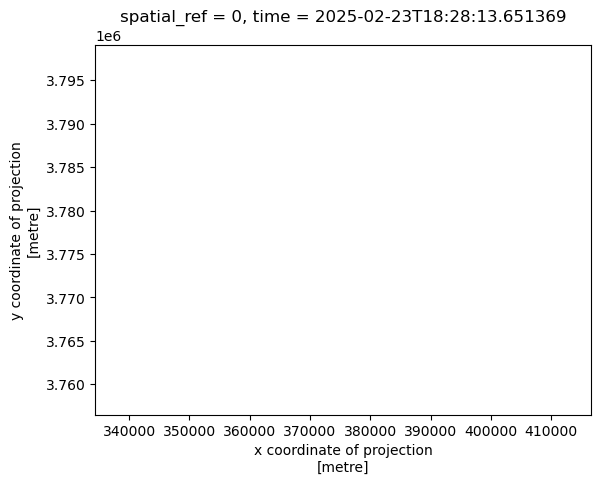

In [16]:
landsat_geo[['red','green','blue']].to_dataarray().plot.imshow()

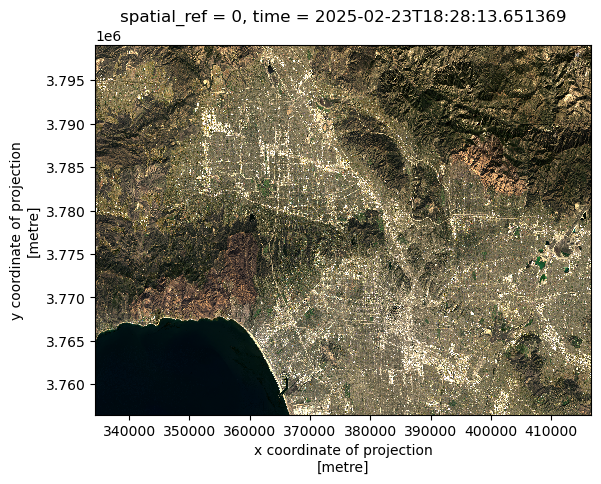

In [17]:
landsat_geo[['red','green','blue']].to_dataarray().plot.imshow(robust=True)

# 6. False color image

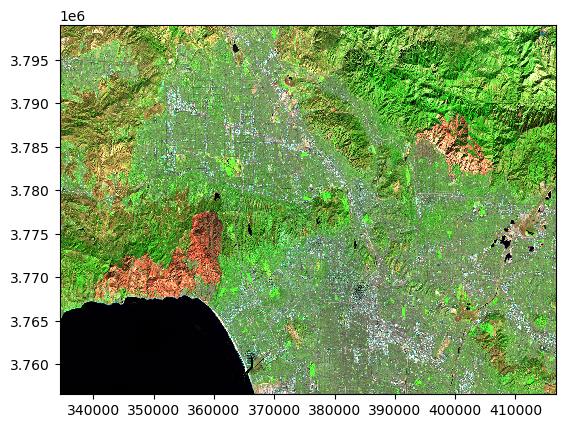

In [18]:
landsat_geo[['swir22','nir08','red']].to_dataarray().plot.imshow(robust = True, add_labels = False)

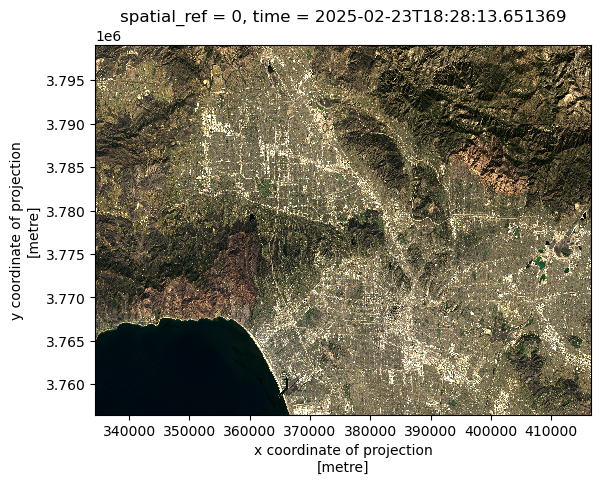

In [19]:
landsat_geo[['red','green','blue']].fillna(0).to_dataarray().plot.imshow(robust = True)

# 7. Map

In [20]:
# CRSs don't match
perimeters.crs == landsat_geo.rio.crs

False

In [21]:
# Match CRSs
perimeters = perimeters.to_crs(crs = landsat_geo.rio.crs) 

In [22]:
# Now the CRSs match
perimeters.crs == landsat_geo.rio.crs


True

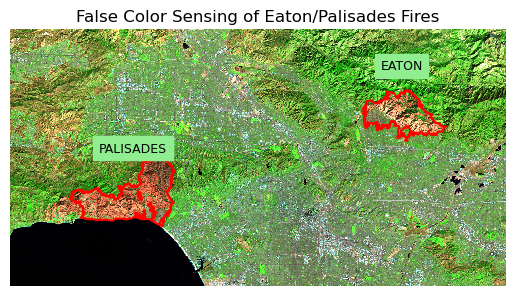

In [ ]:
# Mapping
fig, ax = plt.subplots()
ax.axis('off')

landsat_geo[['swir22','nir08','red']].to_dataarray().plot.imshow(
    robust = True,
    ax = ax,
    add_labels = False)

perimeters.boundary.plot(
    ax = ax,
    color = 'red',
)

ax.set_title('False Color Sensing of Eaton/Palisades Fires')

for n,name in zip(range(0,2),perimeters['FIRE_NAME']):
    ax.text(perimeters.centroid.iloc[n].x ,perimeters.centroid.iloc[n].y + 7500, name, fontsize = 9, color = 'black', ha = 'center', backgroundcolor = 'lightgreen')